# Tutorial Completo: Pipeline Modular 1D de `rl_vmc`

Este notebook interactivo recorre y verifica **todas las características implementadas** en la paquetería modular `rl_vmc`:

1. **Configuración Jerárquica y Banderas (`Experiment1DConfig`, `PostProcessConfig`, `argparse`)**.
2. **Física Cuántica 1D (`Harmonic1DHamiltonian`) y Funciones de Onda (`SlaterJastrow1DAnsatz` y `CASSCF1DAnsatz`)** con todos los modelos de orbitales y correlaciones.
3. **Políticas de Propuesta Clásicas (`Metropolis`, `MALA`, `HMC`) y Neuronales (`DeepSet`, `FlatMLP`)** con modos `residual_mala`, `scale_only`, `full_gaussian` y `use_spatial_gating`.
4. **Motor MCMC (`MHSampler1D`)** en modos `all_electrons`, `single_electron` y `hmc`, más las **4 Funciones de Recompensa RL** (`cdlb`, `log_esjd`, `barker_jump`, `kappa_jump`).
5. **Ejecución de los 4 Regímenes del Pipeline (`vmc_only`, `rl_only`, `coupled`, `eval_only`)** con `TD3` y `REINFORCE`, generando archivos unificados HDF5 (`run_bundle.h5`).
6. **Conversión Bidireccional Legacy (`params.json`, `*.pkl`, `*.csv`) $\leftrightarrow$ HDF5 (`run_bundle.h5`)**.
7. **Post-Procesamiento Modular (`run_postprocessing_pipeline`)**: cálculo de ACF por FFT, IAT de Sokal, ESS/s, $G_{\text{RL}}$, Time-to-Solution, densidades 1D por espín, correlación de pares, picos de Wigner, divergencia KL 2D y visualización de las 6 figuras comparativas.

In [1]:
import os
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

os.environ.setdefault("JAX_ENABLE_X64", "True")

ROOT_DIR = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
if ROOT_DIR not in sys.path:
    sys.path.insert(0, ROOT_DIR)

import rl_vmc
from rl_vmc.config import (
    Experiment1DConfig,
    PostProcessConfig,
    parse_experiment_args,
    parse_postprocess_args,
)

print("Versión de rl_vmc:", rl_vmc.__version__)
print("Dispositivos JAX :", jax.devices())

Versión de rl_vmc: 1.0.0
Dispositivos JAX : [CpuDevice(id=0)]


## 1. Configuración Jerárquica y Parser de Argumentos (`rl_vmc.config`)

Podemos instanciar `Experiment1DConfig` directamente en Python o bien parsear cualquier lista de banderas de línea de comandos con `parse_experiment_args([...])` (incluyendo los atajos `--method {MH, MALA, HMC, TD3, REINFORCE}` y las banderas booleanas `--flag / --no-flag`).

In [2]:
# Ejemplo: parsear argumentos estilo CLI usando el atajo --method TD3 y banderas booleanas
cfg_demo = parse_experiment_args([
    "--method", "TD3",
    "--n_elec", "2", "--n_up", "1", "--n_dn", "1",
    "--omega", "0.1", "--g", "2.0",
    "--use_spatial_gating", "--staggered_critic_reset",
    "--no-export_legacy_files",
])

print("Proposal type autoconfigurado:", cfg_demo.proposal.proposal_type)
print("Train mode autoconfigurado   :", cfg_demo.train.mode)
print("Spatial gating activo        :", cfg_demo.proposal.use_spatial_gating)
print("Recompensa por defecto       :", cfg_demo.rl.reward_type)

# Verificación de serialización y reconstrucción exacta (usada dentro de run_bundle.h5)
cfg_reconstructed = Experiment1DConfig.from_dict(cfg_demo.to_dict())
assert cfg_reconstructed.to_dict() == cfg_demo.to_dict()
print("Serialización to_dict() <-> from_dict() verificada correctamente.")

Proposal type autoconfigurado: neural_deepset
Train mode autoconfigurado   : coupled
Spatial gating activo        : True
Recompensa por defecto       : cdlb
Serialización to_dict() <-> from_dict() verificada correctamente.


## 2. Física 1D (`Harmonic1DHamiltonian`) y Arquitecturas de Función de Onda (`SlaterJastrow1DAnsatz` y `CASSCF1DAnsatz`)

Probamos a continuación:
1. El Hamiltoniano 1D (`noninteracting_reference_energy`, `harmonic_potential`, `interaction_energy`, `local_energy_and_components`).
2. Todas las combinaciones de modelos de orbitales (`ho_fixed`, `ho_variational`, `gaussian_basis`, `backflow_ho`) y factores de correlación (`none`, `jastrow`, `spin_rbf`, `spin_rbf_jastrow`, `spin_rbf_threebody`).
3. La carga y evaluación de una función de onda multideterminantal `CASSCF1DAnsatz` desde un archivo `.npz`.

In [3]:
from rl_vmc.physics.harmonic_1d import Harmonic1DHamiltonian
from rl_vmc.ansatze.ansatz_1d import build_ansatz_1d

OUT_BASE = Path(ROOT_DIR) / "results" / "notebook_pipeline_test"
OUT_BASE.mkdir(parents=True, exist_ok=True)

key = jax.random.PRNGKey(42)
test_walkers = jax.random.normal(key, (16, 3, 1)) * 1.5

# Probar combinaciones de orbital_model y correlation_model para N=3 electrones (incluyendo 3 cuerpos)
orbital_models = ["ho_fixed", "ho_variational", "gaussian_basis", "backflow_ho"]
corr_models = ["none", "jastrow", "spin_rbf", "spin_rbf_jastrow", "spin_rbf_threebody"]

rows_ansatz = []
for orb_m in orbital_models:
    for corr_m in corr_models:
        c = Experiment1DConfig()
        c.system.n_elec, c.system.n_up, c.system.n_dn = 3, 2, 1
        c.ansatz.orbital_model = orb_m
        c.ansatz.correlation_model = corr_m
        ans = build_ansatz_1d(c)
        ham = Harmonic1DHamiltonian(c.system)
        p_psi = ans.init(key, test_walkers)
        lp, glp = ans.value_and_grad(p_psi, test_walkers)
        eloc, tloc, vloc = ham.local_energy_and_components(ans.apply, p_psi, test_walkers)
        rows_ansatz.append({
            "orbital_model": orb_m,
            "correlation_model": corr_m,
            "mean_log_psi": float(jnp.mean(lp)),
            "mean_E_loc": float(jnp.mean(eloc)),
            "mean_T_loc": float(jnp.mean(tloc)),
            "mean_V_loc": float(jnp.mean(vloc)),
        })

df_ansatz_check = pd.DataFrame(rows_ansatz)
print(f"Probadas {len(df_ansatz_check)} combinaciones de SlaterJastrow1DAnsatz sin errores:")
print(df_ansatz_check.head(8).to_string(index=False))

Probadas 20 combinaciones de SlaterJastrow1DAnsatz sin errores:
 orbital_model  correlation_model  mean_log_psi  mean_E_loc  mean_T_loc  mean_V_loc
      ho_fixed               none     -3.579918    2.924800   -0.707655    3.632455
      ho_fixed            jastrow     -3.008602    3.205169   -0.427286    3.632455
      ho_fixed           spin_rbf     -3.012794    3.002586   -0.629869    3.632455
      ho_fixed   spin_rbf_jastrow     -2.441478    3.262297   -0.370159    3.632455
      ho_fixed spin_rbf_threebody     -2.982086    3.002659   -0.629796    3.632455
ho_variational               none     -3.579918    2.924800   -0.707655    3.632455
ho_variational            jastrow     -3.008602    3.205169   -0.427286    3.632455
ho_variational           spin_rbf     -3.012794    3.002586   -0.629869    3.632455


In [4]:
# Crear un archivo .npz sintético de prueba para verificar CASSCF1DAnsatz (congelado y entrenable)
casscf_npz_file = OUT_BASE / "synthetic_casscf_c0-a3.npz"
n_basis_test = 4
meta_dict = {
    "config": {
        "omega": 0.1,
        "n_up": 1,
        "n_down": 1,
        "n_basis": n_basis_test,
        "n_core": 0,
        "n_active": 3,
    }
}
# 3 determinantes en espacio activo de 3 orbitales (máscaras de bits para up y down)
np.savez(
    casscf_npz_file,
    metadata_json=json.dumps(meta_dict),
    orbital_coefficients=np.eye(n_basis_test, dtype=np.float64),
    selected_ci_coefficients=np.array([0.92, -0.30, -0.25], dtype=np.float64),
    selected_ci_determinants=np.array([1 | (1 << 3), 2 | (2 << 3), 4 | (4 << 3)], dtype=np.int64),
)

cfg_casscf = Experiment1DConfig()
cfg_casscf.system.n_elec, cfg_casscf.system.n_up, cfg_casscf.system.n_dn = 2, 1, 1
cfg_casscf.ansatz.ansatz_type = "casscf_npz"
cfg_casscf.ansatz.casscf_npz_path = str(casscf_npz_file)
cfg_casscf.ansatz.casscf_trainable = True

casscf_ans = build_ansatz_1d(cfg_casscf)
w_2e = jax.random.normal(key, (8, 2, 1))
p_casscf = casscf_ans.init(key, w_2e)
lp_c, glp_c = casscf_ans.value_and_grad(p_casscf, w_2e)
print("CASSCF1DAnsatz verificado -> log|Psi| medio:", float(jnp.mean(lp_c)), "| shape grad:", glp_c.shape)

CASSCF1DAnsatz verificado -> log|Psi| medio: -2.0125174828234367 | shape grad: (8, 2, 1)


## 3. Políticas de Propuesta Clásicas y Neuronales (`rl_vmc.proposals`)

Verificamos los 5 tipos de propuesta (`metropolis`, `mala`, `hmc`, `neural_deepset`, `neural_flat`), los 3 modos de acción neuronal (`residual_mala`, `scale_only`, `full_gaussian`) y el funcionamiento de `--use_spatial_gating`.

In [5]:
from rl_vmc.proposals.proposals_1d import build_proposal_1d

for ptype in ["metropolis", "mala", "hmc", "neural_deepset", "neural_flat"]:
    for pmode in (["residual_mala", "scale_only", "full_gaussian"] if "neural" in ptype else ["residual_mala"]):
        c = Experiment1DConfig()
        c.system.n_elec, c.system.n_up, c.system.n_dn = 2, 1, 1
        c.proposal.proposal_type = ptype
        c.proposal.proposal_mode = pmode
        c.proposal.use_spatial_gating = True
        prop = build_proposal_1d(c)
        p_act = prop.init_params(key, w_2e, glp_c)
        mu, sigma, aux = prop.distribution(p_act, w_2e, glp_c, use_actor=True, key_explore=key, exploration_std=0.1)
        print(
            f"Proposal={ptype:14s} | mode={pmode:13s} | "
            f"mu.shape={mu.shape} | <sigma>={float(jnp.mean(sigma)):.4f}"
        )

Proposal=metropolis     | mode=residual_mala | mu.shape=(8, 2, 1) | <sigma>=0.5000
Proposal=mala           | mode=residual_mala | mu.shape=(8, 2, 1) | <sigma>=0.1414
Proposal=hmc            | mode=residual_mala | mu.shape=(8, 2, 1) | <sigma>=0.1414
Proposal=neural_deepset | mode=residual_mala | mu.shape=(8, 2, 1) | <sigma>=0.1470
Proposal=neural_deepset | mode=scale_only    | mu.shape=(8, 2, 1) | <sigma>=0.1470
Proposal=neural_deepset | mode=full_gaussian | mu.shape=(8, 2, 1) | <sigma>=0.1470
Proposal=neural_flat    | mode=residual_mala | mu.shape=(8, 2, 1) | <sigma>=0.1526
Proposal=neural_flat    | mode=scale_only    | mu.shape=(8, 2, 1) | <sigma>=0.1526
Proposal=neural_flat    | mode=full_gaussian | mu.shape=(8, 2, 1) | <sigma>=0.1526


## 4. Motor MCMC (`MHSampler1D`) y las 4 Funciones de Recompensa RL (`rl_vmc.rl.rewards`)

Probamos un paso de muestreo con `all_electrons`, `single_electron` y `hmc`, y evaluamos las 4 recompensas (`cdlb`, `log_esjd`, `barker_jump`, `kappa_jump`).

In [6]:
from rl_vmc.samplers.mh_sampler_1d import MHSampler1D
from rl_vmc.rl.rewards import compute_rl_reward

for upd_mode, ptype in [("all_electrons", "neural_deepset"), ("single_electron", "neural_deepset"), ("all_electrons", "hmc")]:
    c = Experiment1DConfig()
    c.system.n_elec, c.system.n_up, c.system.n_dn = 2, 1, 1
    c.sampler.batch_size = 32
    c.sampler.update_mode = upd_mode
    c.proposal.proposal_type = ptype
    ans = build_ansatz_1d(c)
    prop = build_proposal_1d(c)
    samp = MHSampler1D(c, ans, prop)
    p_psi = ans.init(key, jnp.zeros((32, 2, 1)))
    st = samp.init_state(key, p_psi)
    p_act = prop.init_params(key, st.walkers, st.grad_log_psi)
    st_next, stats, rl_info = samp.step(key, st, p_psi, p_act, use_actor=True, exploration_std=0.05)

    rewards_summary = {}
    for rtype in ["cdlb", "log_esjd", "barker_jump", "kappa_jump"]:
        c.rl.reward_type = rtype
        r_val, _ = compute_rl_reward(rl_info, c)
        rewards_summary[rtype] = round(float(jnp.mean(r_val)), 4)

    print(
        f"Modo={upd_mode:15s} ({ptype:14s}) -> Acc={float(jnp.mean(stats.acceptance)):.2%}, "
        f"ESJD={float(jnp.mean(stats.esjd)):.5f} | Recompensas={rewards_summary}"
    )

Modo=all_electrons   (neural_deepset) -> Acc=93.75%, ESJD=0.02876 | Recompensas={'cdlb': -0.0917, 'log_esjd': -4.6248, 'barker_jump': 0.5996, 'kappa_jump': 0.1306}
Modo=single_electron (neural_deepset) -> Acc=98.44%, ESJD=0.03726 | Recompensas={'cdlb': -0.0676, 'log_esjd': -4.2923, 'barker_jump': 0.6898, 'kappa_jump': 0.1433}
Modo=all_electrons   (hmc           ) -> Acc=100.00%, ESJD=0.17606 | Recompensas={'cdlb': 0.2439, 'log_esjd': -3.0437, 'barker_jump': 1.3028, 'kappa_jump': 0.2414}


## 5. Ejecución de los 4 Regímenes del Pipeline (`vmc_only`, `coupled`, `rl_only`, `eval_only`)

Ahora ejecutamos el orquestador maestro `run_experiment_1d` para generar archivos unificados HDF5 (`.h5`) en cada uno de los regímenes de operación:
1. **`mala_bundle.h5`**: Entrenamiento VMC con MALA clásico (`vmc_only`).
2. **`hmc_bundle.h5`**: Entrenamiento VMC con Hamiltonian Monte Carlo (`vmc_only`).
3. **`td3_deepset_bundle.h5`**: Entrenamiento acoplado VMC + RL-MALA (`coupled` con `TD3`, `neural_deepset`, recompensa `cdlb`, `use_spatial_gating` y `staggered_critic_reset`).
4. **`reinforce_bundle.h5`**: Entrenamiento exclusivo del Actor con `REINFORCE` reparametrizado (`rl_only` con recompensa `kappa_jump`) cargando el Ansatz ya entrenado en el paso 3.
5. **`eval_only_actor_on.h5`**: Evaluación pura (`eval_only`) cargando el Ansatz y el Actor entrenados desde `td3_deepset_bundle.h5`.

In [7]:
from rl_vmc.trainers.runner_1d import run_experiment_1d

# 5.1 Experimento A: MALA Clásico (vmc_only)
cfg_mala = parse_experiment_args([
    "--method", "MALA",
    "--n_elec", "2", "--n_up", "1", "--n_dn", "1",
    "--omega", "0.1", "--g", "2.0",
    "--batch_size", "128",
    "--n_burn_in", "40",
    "--train_steps", "40", "--n_print", "20", "--n_log", "10",
    "--eval_burn_in", "40", "--measure_steps", "120", "--jit_chunk_size", "60",
    "--output_h5", str(OUT_BASE / "mala_bundle.h5"),
])
h5_mala = run_experiment_1d(cfg_mala)

# 5.2 Experimento B: HMC Clásico (vmc_only)
cfg_hmc = parse_experiment_args([
    "--method", "HMC",
    "--n_elec", "2", "--n_up", "1", "--n_dn", "1",
    "--omega", "0.1", "--g", "2.0",
    "--hmc_leapfrog_steps", "4", "--hmc_step_size", "0.05",
    "--batch_size", "128",
    "--n_burn_in", "40",
    "--train_steps", "40", "--n_print", "20", "--n_log", "10",
    "--eval_burn_in", "40", "--measure_steps", "120", "--jit_chunk_size", "60",
    "--output_h5", str(OUT_BASE / "hmc_bundle.h5"),
])
h5_hmc = run_experiment_1d(cfg_hmc)

[RL-VMC 1D] Iniciando Experimento -> /Users/romanarmenta/Documents/Git-Projects/RL-VMC-main/results/notebook_pipeline_test/mala_bundle.h5
  Sistema   : N=2 (up=1, dn=1), omega=0.1, g=2.0, soft=0.1
  Ansatz    : slater_jastrow_1d (orbital=backflow_ho, corr=spin_rbf_jastrow)
  Propuesta : mala (modo=residual_mala, tau=0.01, update=all_electrons)
  Régimen   : vmc_only
[MCMC] Termalizando caminantes iniciales (40 pasos)...
[Train] Modo vmc_only (40 pasos)...
  [VMC    1/40] E=2.976674 (Var=15.8286) | Acc=92.97% | ESJD=0.03828
  [VMC   20/40] E=3.650769 (Var=16.0415) | Acc=93.75% | ESJD=0.04198
  [VMC   40/40] E=4.162524 (Var=18.4859) | Acc=93.75% | ESJD=0.04182

[Eval] Ejecutando 1 cadena(s) de producción (burn_in=40, measure_steps=120, thin=1, use_actor=False)...
  -> [Cadena 0] <E> = 4.109374 +/- 0.045390 Ha | Acc = 94.87% | ESJD = 0.03717 | t = 0.94s

[IO] Archivo unificado HDF5 guardado en: /Users/romanarmenta/Documents/Git-Projects/RL-VMC-main/results/notebook_pipeline_test/mala_bund

In [8]:
# 5.3 Experimento C: Entrenamiento Acoplado VMC + TD3 DeepSet (coupled)
cfg_td3 = parse_experiment_args([
    "--method", "TD3",
    "--n_elec", "2", "--n_up", "1", "--n_dn", "1",
    "--omega", "0.1", "--g", "2.0",
    "--reward_type", "cdlb",
    "--use_spatial_gating", "--staggered_critic_reset",
    "--batch_size", "128", "--rl_batch_size", "64",
    "--n_burn_in", "40",
    "--coupled_training_cycles", "2",
    "--rl_sweeps_per_cycle", "15",
    "--vmc_iterations_per_cycle", "20",
    "--n_print", "10", "--n_log", "5",
    "--eval_burn_in", "40", "--measure_steps", "120", "--jit_chunk_size", "60",
    "--output_h5", str(OUT_BASE / "td3_deepset_bundle.h5"),
])
h5_td3 = run_experiment_1d(cfg_td3)

[RL-VMC 1D] Iniciando Experimento -> /Users/romanarmenta/Documents/Git-Projects/RL-VMC-main/results/notebook_pipeline_test/td3_deepset_bundle.h5
  Sistema   : N=2 (up=1, dn=1), omega=0.1, g=2.0, soft=0.1
  Ansatz    : slater_jastrow_1d (orbital=backflow_ho, corr=spin_rbf_jastrow)
  Propuesta : neural_deepset (modo=residual_mala, tau=0.01, update=all_electrons)
  Régimen   : coupled
[MCMC] Termalizando caminantes iniciales (40 pasos)...
[Train] Modo acoplado VMC + RL (2 ciclos)...

--- Ciclo Acoplado 1/2 ---
  [C1-RL    1/15] Reward=-0.0552 | Acc=89.06% | ESJD=0.03220 | L_critic=0.1299
  [C1-RL    5/15] Reward=-0.0750 | Acc=86.72% | ESJD=0.03110 | L_critic=0.1110
  [C1-RL   10/15] Reward=-0.0755 | Acc=87.50% | ESJD=0.03268 | L_critic=0.0721
  [C1-RL   15/15] Reward=-0.0864 | Acc=90.62% | ESJD=0.03208 | L_critic=0.0473
  [C1-VMC    1/20] E=3.349664 (Var=15.7123) | Acc=89.84% | ESJD=0.03261
  [C1-VMC   10/20] E=3.970443 (Var=18.3532) | Acc=92.97% | ESJD=0.03274
  [C1-VMC   20/20] E=4.1870

In [9]:
# 5.4 Experimento D: Entrenamiento RL-Only con REINFORCE Reparametrizado sobre Ansatz Congelado
cfg_reinf = parse_experiment_args([
    "--method", "REINFORCE",
    "--train_mode", "rl_only",
    "--n_elec", "2", "--n_up", "1", "--n_dn", "1",
    "--omega", "0.1", "--g", "2.0",
    "--reward_type", "kappa_jump",
    "--load_bundle_h5", str(h5_td3),
    "--batch_size", "128",
    "--n_burn_in", "30",
    "--rl_sweeps_per_cycle", "20",
    "--n_print", "10", "--n_log", "5",
    "--eval_burn_in", "40", "--measure_steps", "120", "--jit_chunk_size", "60",
    "--output_h5", str(OUT_BASE / "reinforce_bundle.h5"),
])
h5_reinf = run_experiment_1d(cfg_reinf)

# 5.5 Experimento E: Modo eval_only cargando Ansatz + Actor congelados desde td3_deepset_bundle.h5
cfg_eval = parse_experiment_args([
    "--train_mode", "eval_only",
    "--proposal_type", "neural_deepset",
    "--n_elec", "2", "--n_up", "1", "--n_dn", "1",
    "--omega", "0.1", "--g", "2.0",
    "--load_bundle_h5", str(h5_td3),
    "--use_actor_in_eval",
    "--batch_size", "128",
    "--eval_burn_in", "40", "--measure_steps", "120", "--jit_chunk_size", "60",
    "--output_h5", str(OUT_BASE / "eval_only_actor_on.h5"),
])
h5_eval = run_experiment_1d(cfg_eval)

[RL-VMC 1D] Iniciando Experimento -> /Users/romanarmenta/Documents/Git-Projects/RL-VMC-main/results/notebook_pipeline_test/reinforce_bundle.h5
  Sistema   : N=2 (up=1, dn=1), omega=0.1, g=2.0, soft=0.1
  Ansatz    : slater_jastrow_1d (orbital=backflow_ho, corr=spin_rbf_jastrow)
  Propuesta : neural_deepset (modo=residual_mala, tau=0.01, update=all_electrons)
  Régimen   : rl_only
[IO] Cargando checkpoints desde HDF5: /Users/romanarmenta/Documents/Git-Projects/RL-VMC-main/results/notebook_pipeline_test/td3_deepset_bundle.h5
  -> Pesos del Ansatz restaurados desde HDF5.
  -> Pesos del Actor restaurados desde HDF5.
[MCMC] Termalizando caminantes iniciales (30 pasos)...
[Train] Modo rl_only (20 barridos RL)...
  [RL    1/20] Reward=+0.1416 | Acc=79.69% | ESJD=0.03484 | L_critic=0.0000
  [RL    5/20] Reward=+0.1438 | Acc=89.06% | ESJD=0.02894 | L_critic=0.0000
  [RL   10/20] Reward=+0.1433 | Acc=85.94% | ESJD=0.03352 | L_critic=0.0000
  [RL   15/20] Reward=+0.1374 | Acc=79.69% | ESJD=0.0322

## 6. Conversión Bidireccional Legacy (`params.json`, `*.pkl`, `*.csv`) $\leftrightarrow$ HDF5 Unificado

Demostramos cómo exportar cualquier archivo `.h5` al formato clásico de archivos sueltos (`params.json`, `TD3_ansatz_weights.pkl`, `TD3_actor_weights.pkl`, `training_metrics.csv`, `measurement_data.csv`) y cómo volver a convertir esa carpeta legacy en un archivo `.h5` unificado.

In [10]:
from rl_vmc.core.io_bundle import (
    export_h5_to_legacy_dir,
    convert_legacy_dir_to_h5,
    load_run_bundle_h5,
)

legacy_folder = OUT_BASE / "legacy_exported_td3"
export_h5_to_legacy_dir(h5_td3, legacy_folder)
print("Archivos exportados en carpeta legacy:", sorted(p.name for p in legacy_folder.iterdir()))

# Ahora convertimos esa carpeta legacy de vuelta a un archivo .h5 unificado
reconverted_h5 = OUT_BASE / "td3_reconverted_from_legacy.h5"
convert_legacy_dir_to_h5(legacy_folder, output_h5_path=reconverted_h5)

bundle_reconv = load_run_bundle_h5(reconverted_h5, load_walkers=False)
print("Checkpoints restaurados en el .h5 convertido:", list(bundle_reconv["checkpoints"].keys()))
print("Filas en training_df restaurado            :", len(bundle_reconv["training_df"]))

Archivos exportados en carpeta legacy: ['TD3_actor_weights.pkl', 'TD3_ansatz_weights.pkl', 'TD3_critic1_weights.pkl', 'TD3_critic2_weights.pkl', 'measurement_data.csv', 'params.json', 'training_metrics.csv']
Checkpoints restaurados en el .h5 convertido: ['actor_final', 'ansatz_best', 'ansatz_final', 'critic1_final', 'critic2_final']
Filas en training_df restaurado            : 28


## 7. Post-Procesamiento Modular Multi-Corrida (`rl_vmc.postprocess`)

Pasamos los archivos `.h5` generados (`MALA`, `HMC`, `TD3-DeepSet`, `REINFORCE`) al módulo de post-procesamiento para:
1. Calcular la tabla comparativa `summary_metrics.csv` (incluyendo $\tau_{\text{int}, E}$ de Sokal, $\text{ESS/s}$, $G_{\text{RL}}$, Time-to-Solution, picos de Wigner y divergencia KL 2D).
2. Generar y visualizar en línea las figuras comparativas.

In [11]:
from rl_vmc.postprocess.plotter import run_postprocessing_pipeline
from IPython.display import Image, display

pp_out_dir = OUT_BASE / "postprocess_comparison"
pp_cfg = PostProcessConfig(
    inputs=[str(h5_mala), str(h5_hmc), str(h5_td3), str(h5_reinf)],
    labels=["MALA", "HMC", "RL-MALA (TD3)", "RL-MALA (REINFORCE)"],
    out_dir=str(pp_out_dir),
    plot_kl_divergence=True,
    figure_format="both",
    dpi=150,
)

df_summary = run_postprocessing_pipeline(pp_cfg)
print("\nColumnas completas exportadas en summary_metrics.csv:")
print(list(df_summary.columns))
print("\nArchivos generados en la carpeta de post-procesamiento:")
for p in sorted(pp_out_dir.iterdir()):
    print(" -", p.name)

[PostProcess] Procesando 'MALA' desde /Users/romanarmenta/Documents/Git-Projects/RL-VMC-main/results/notebook_pipeline_test/mala_bundle.h5...
[PostProcess] Procesando 'HMC' desde /Users/romanarmenta/Documents/Git-Projects/RL-VMC-main/results/notebook_pipeline_test/hmc_bundle.h5...
[PostProcess] Procesando 'RL-MALA (TD3)' desde /Users/romanarmenta/Documents/Git-Projects/RL-VMC-main/results/notebook_pipeline_test/td3_deepset_bundle.h5...
[PostProcess] Procesando 'RL-MALA (REINFORCE)' desde /Users/romanarmenta/Documents/Git-Projects/RL-VMC-main/results/notebook_pipeline_test/reinforce_bundle.h5...
[PostProcess] Tabla resumen guardada en: /Users/romanarmenta/Documents/Git-Projects/RL-VMC-main/results/notebook_pipeline_test/postprocess_comparison/summary_metrics.csv

[PostProcess] Resumen Comparativo de Corridas:
              label   E_mean     SE_E  acceptance     ESJD  tau_int_E  G_RL_speedup  ESS_per_sec
               MALA 4.109374 0.184059    0.948698 0.037171  15.000073      1.000000

=== fig1_training_dashboard.png ===
=== fig2_production_summary.png ===
=== fig3_observables_comparison.png ===
=== fig4_efficiency_bars.png ===
=== fig5_time_to_solution.png ===
=== fig6_walker_traces.png ===


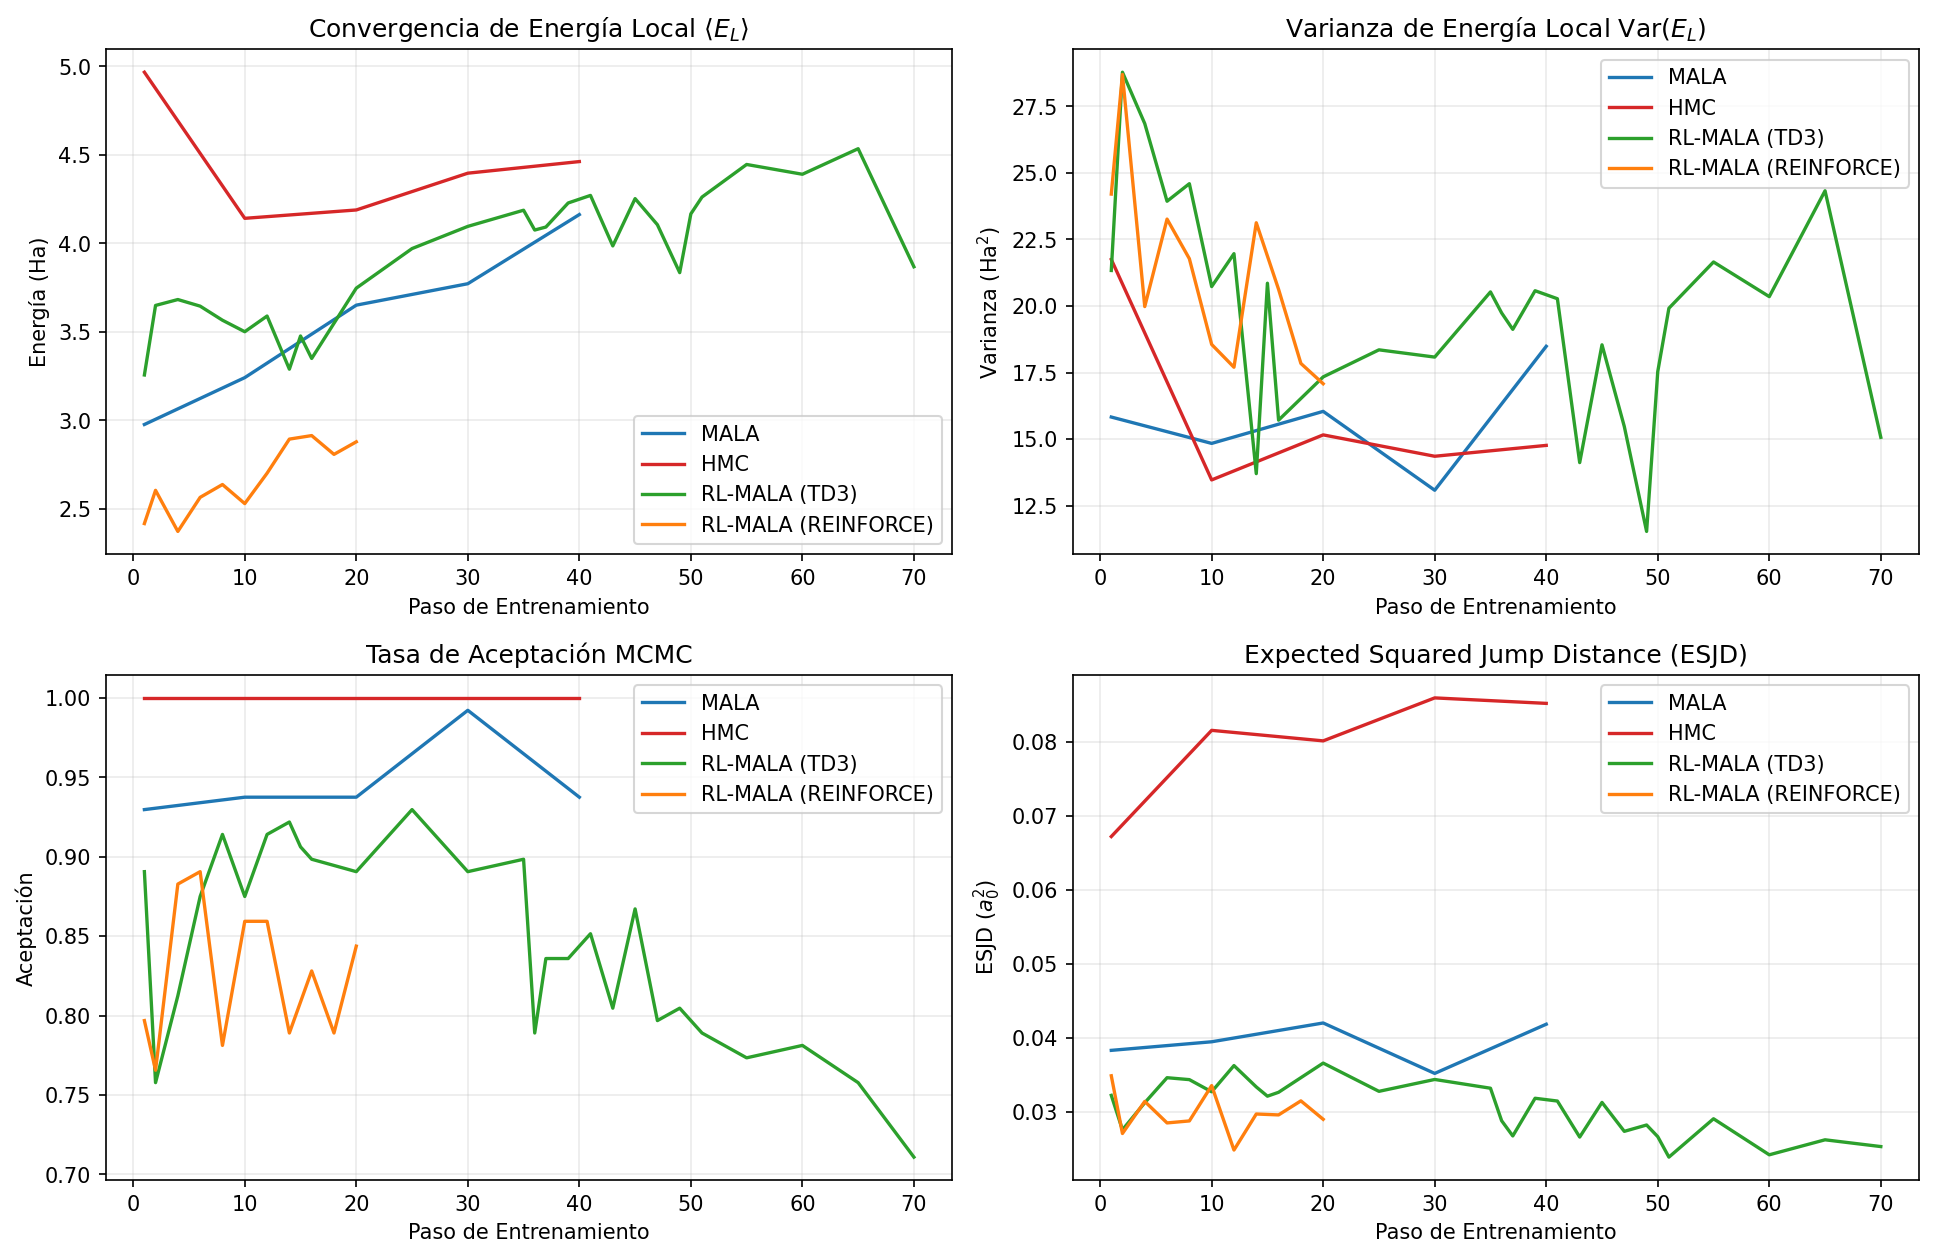

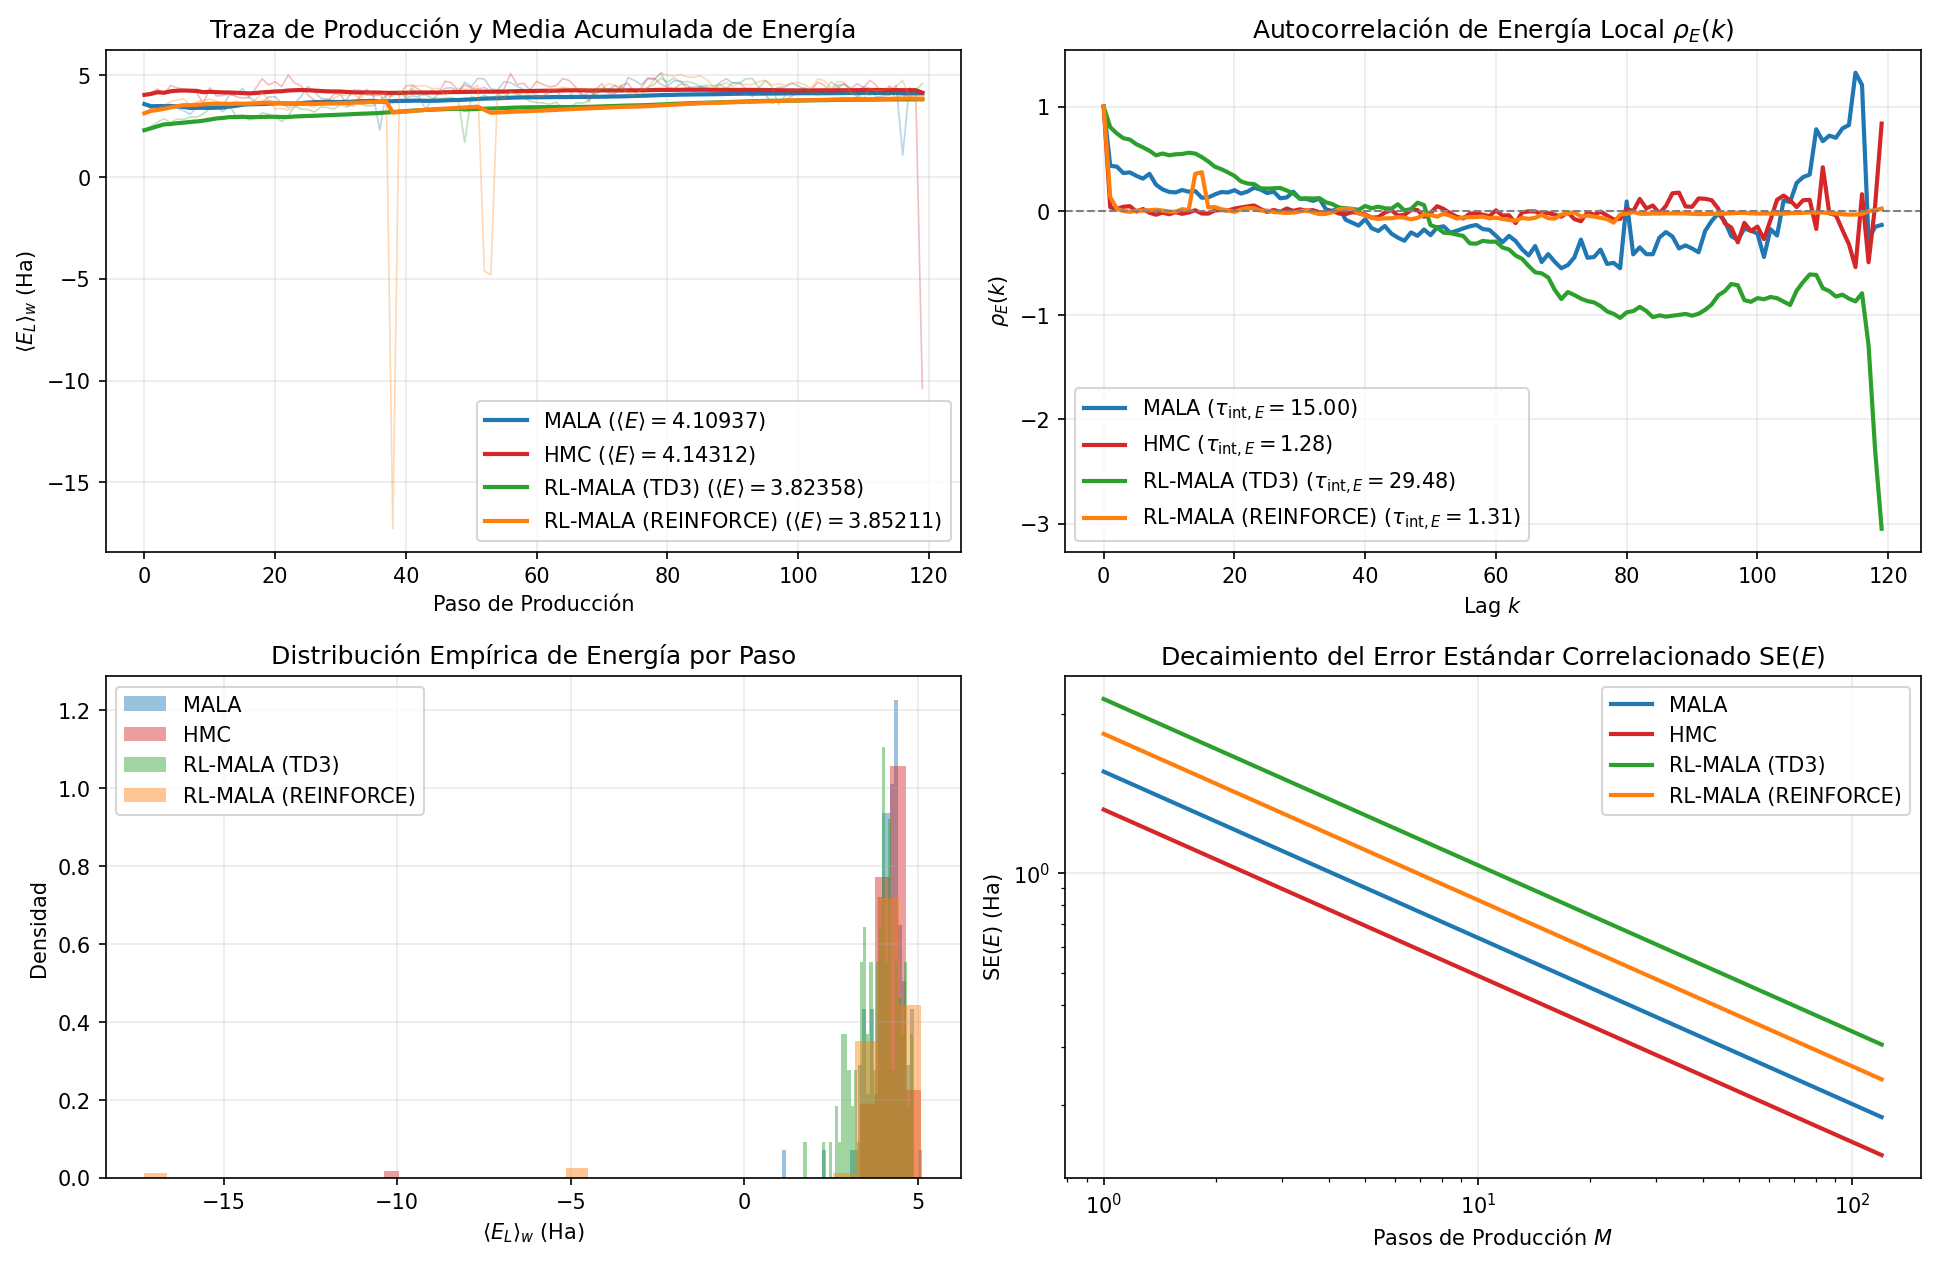

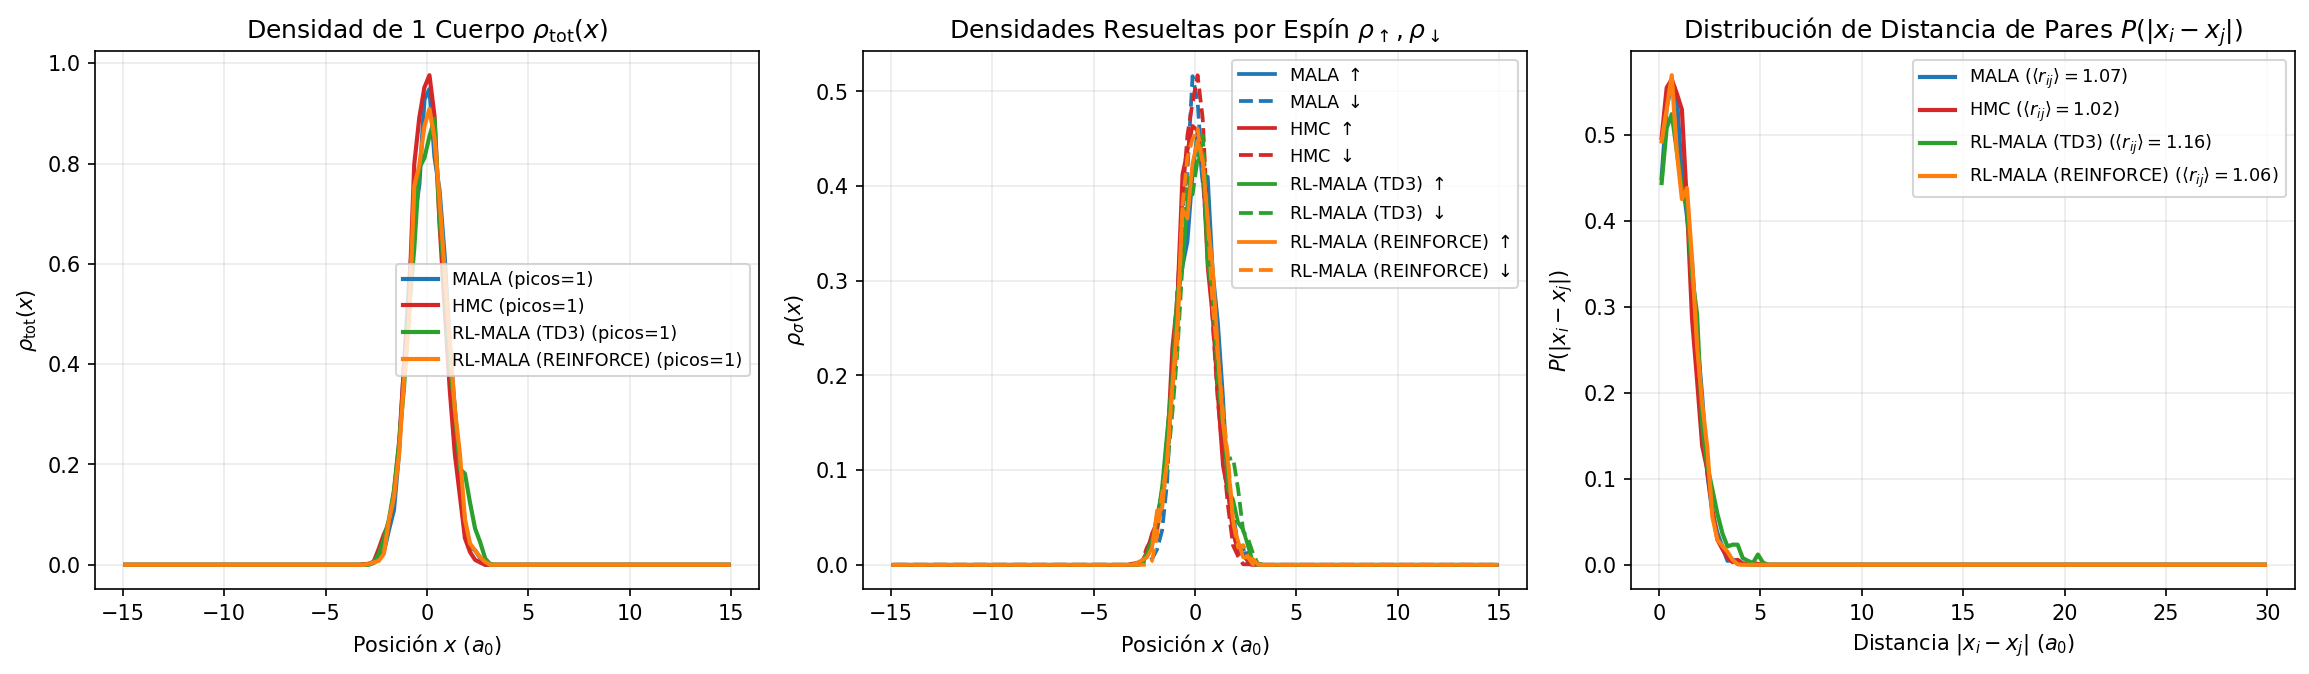

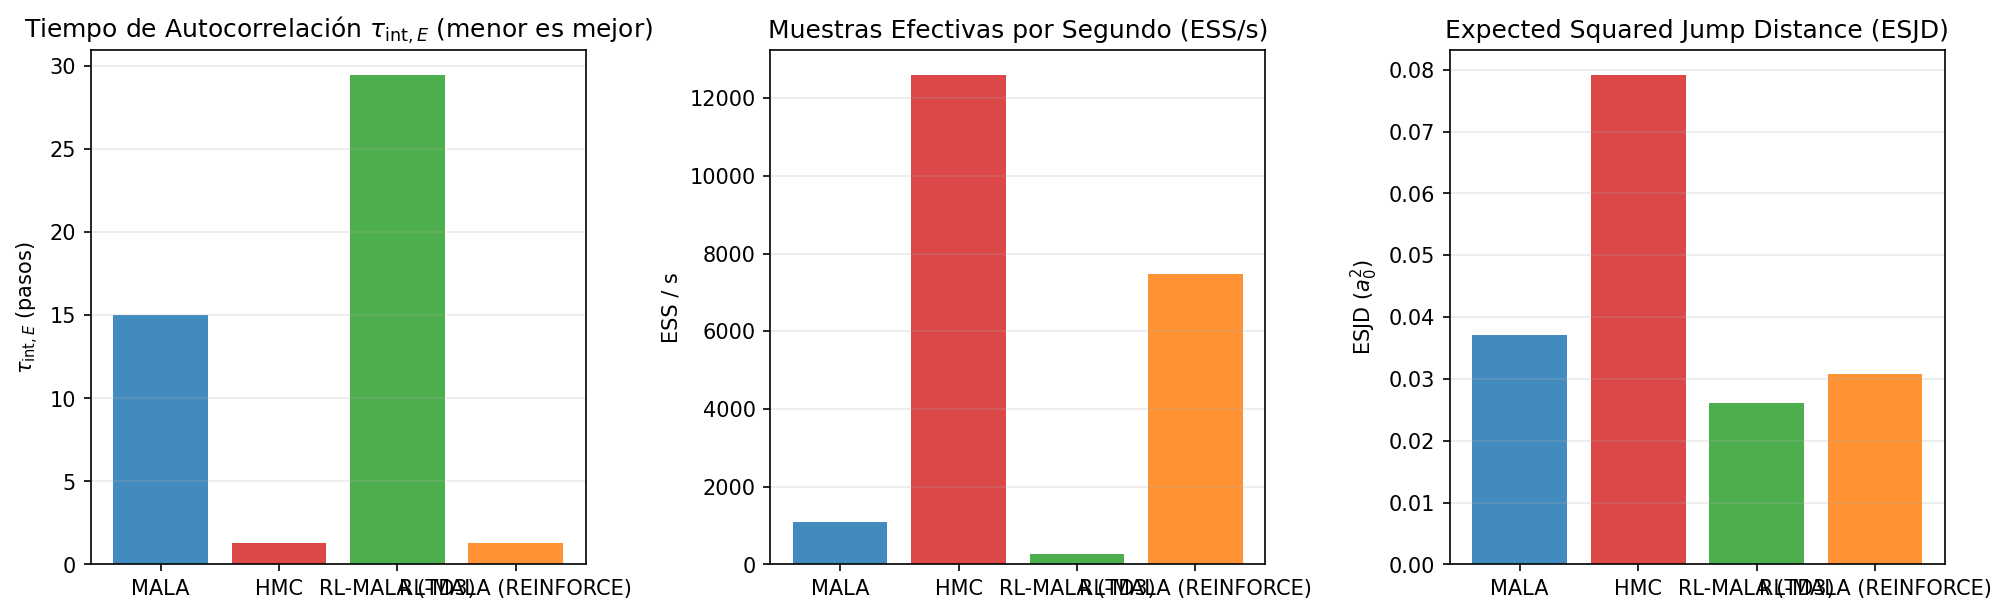

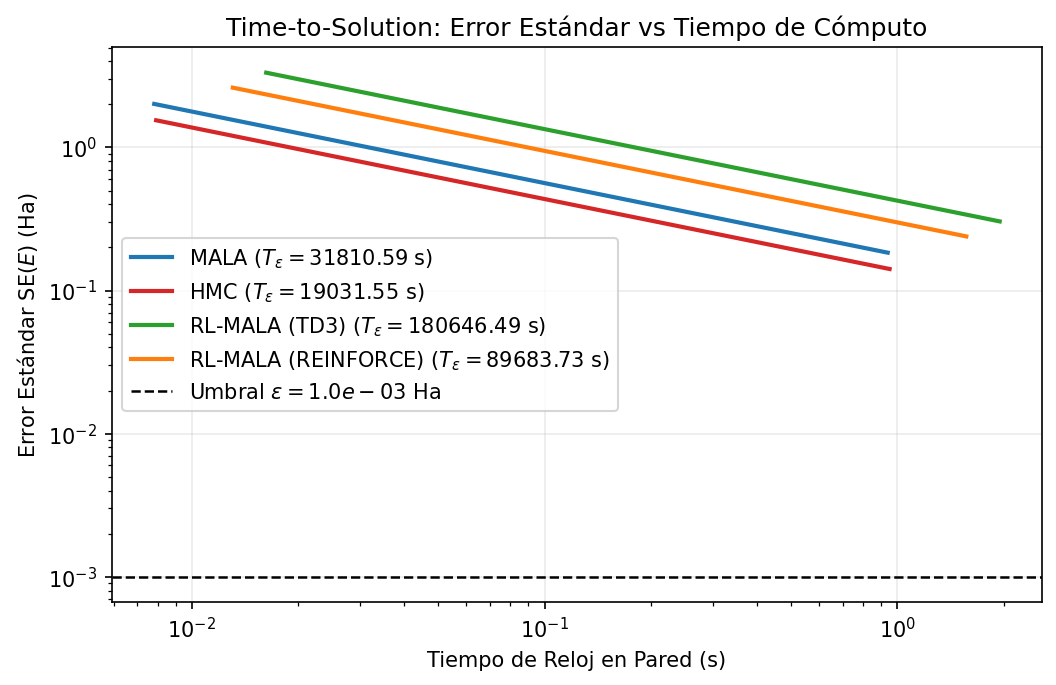

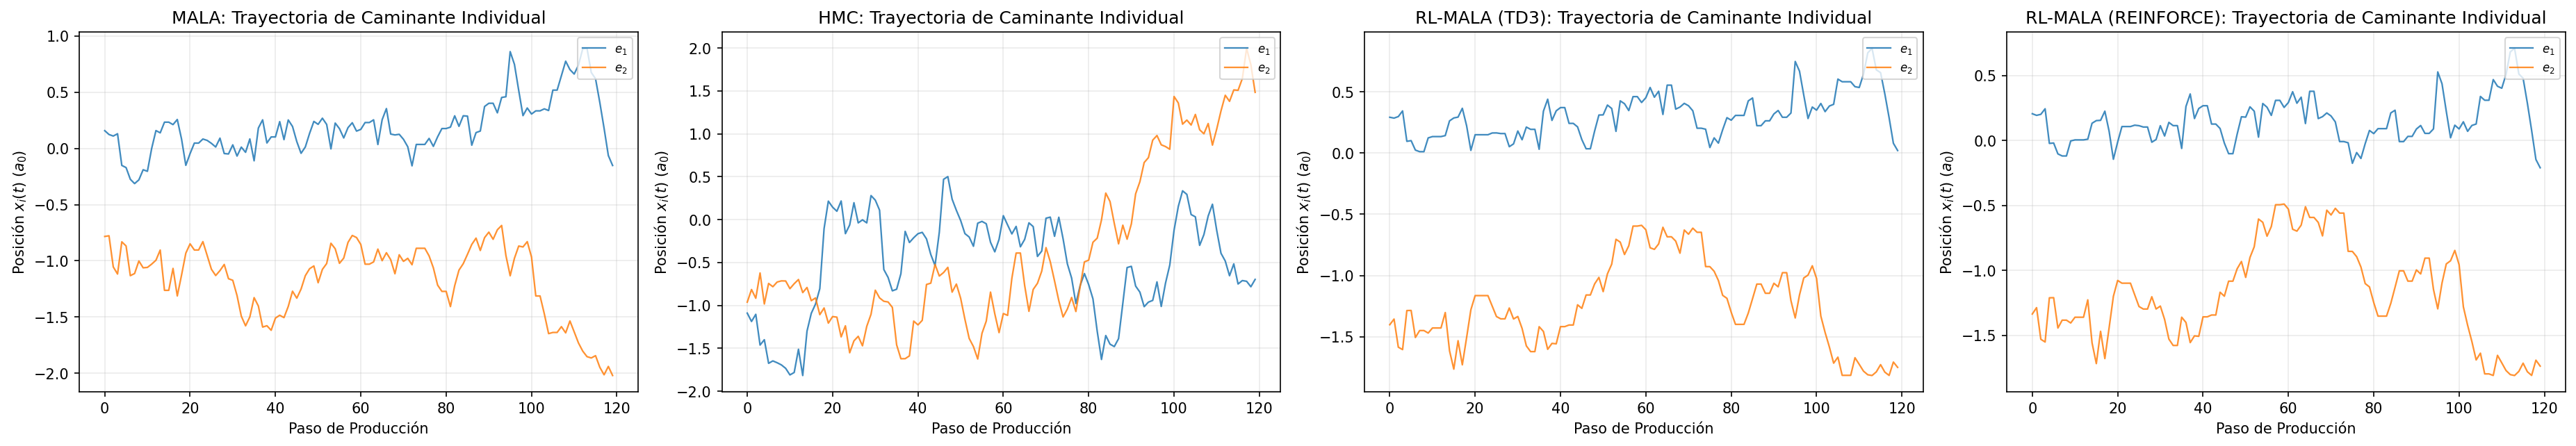

In [12]:
# Visualizar las figuras PNG generadas directamente en la salida de la celda
for fig_name in [
    "fig1_training_dashboard.png",
    "fig2_production_summary.png",
    "fig3_observables_comparison.png",
    "fig4_efficiency_bars.png",
    "fig5_time_to_solution.png",
    "fig6_walker_traces.png",
]:
    fig_path = pp_out_dir / fig_name
    if fig_path.exists():
        print(f"=== {fig_name} ===")
        display(Image(filename=str(fig_path)))